In [1]:
# ==============================================================================
# Import modules
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np
from sklearn import datasets
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import warnings 
warnings.filterwarnings('ignore') 

/Applications/Anaconda/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
# ==============================================================================
# Load data and select features
# ==============================================================================

data = datasets.load_wine()
features = [0, 10]
X = data.data[:, features]
y = data.target
feature_names = [data.feature_names[i] for i in features]

In [3]:
# ==============================================================================
# Split into training and test data
# ==============================================================================

# Split data into training and test data (70% training, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=3, stratify=y)


In [4]:
# ==============================================================================
# Scale features using StandardScaler class in scikit-learn
# ==============================================================================

# Initialise standard scaler and compute mean and stddev from training data
sc = StandardScaler()
sc.fit(X_train)

# Transform (standardise) both X_train and X_test with mean and stddev from
# training data
X_train_sc = sc.transform(X_train)
X_test_sc = sc.transform(X_test)


In [5]:
# ==============================================================================
# Multiclass perceptron (with optimised hyperparameters)
# ==============================================================================

ppn=Perceptron(eta0=0.0001, max_iter=1)

# Fit the model
ppn.fit(X_train_sc, y_train)

# Make predictions for the test set
y_pred_ppn = ppn.predict(X_test_sc)
print("Misclassified samples: {0}".format((y_test != y_pred_ppn).sum()))

# Print accuracy computed from predictions on the test set
print("Accuracy: {0:.2f}".format(ppn.score(X_test_sc, y_test)))

Misclassified samples: 11
Accuracy: 0.80


In [6]:
# ==============================================================================
# Logistic regression (with optimised hyperparameters)
# ==============================================================================

logR=LogisticRegression(C=10)

# Fit the model
logR.fit(X_train_sc, y_train)

# Make predictions for the test set
y_pred_logR = logR.predict(X_test_sc)

print("Misclassified samples: {0}".format((y_test != y_pred_logR).sum()))

# Print accuracy computed from predictions on the test set
print("Accuracy: {0:.2f}".format(logR.score(X_test_sc, y_test)))

Misclassified samples: 8
Accuracy: 0.85


In [7]:
# ==============================================================================
# SVM (with optimised hyperparameters)
# ==============================================================================

svm=SVC(C=10, gamma=0.1, kernel='rbf')

# Fit the model
svm.fit(X_train_sc, y_train)

# Make predictions for the test set
y_pred_SVC = svm.predict(X_test_sc)

print("Misclassified samples: {0}".format((y_test != y_pred_SVC).sum()))

# Print accuracy computed from predictions on the test set
print("Accuracy: {0:.2f}".format(svm.score(X_test_sc, y_test)))

Misclassified samples: 5
Accuracy: 0.91


Misclassified samples: 7
Accuracy: 0.87


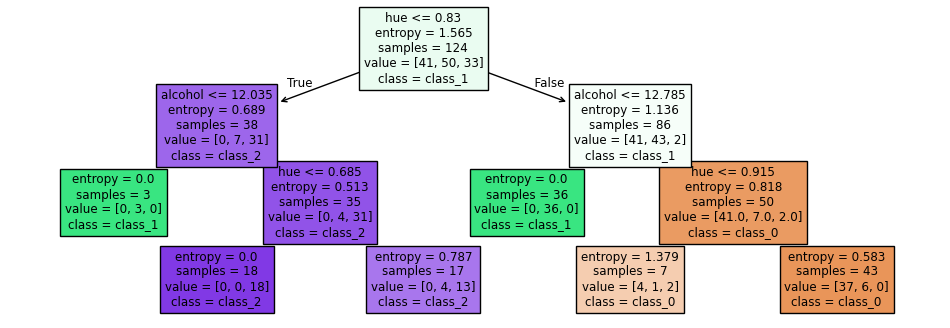

In [8]:
# ==============================================================================
# Decision Tree (with optimised hyperparameters)
# ==============================================================================

DT=DecisionTreeClassifier(criterion='entropy', max_depth=3, min_samples_split=2)

# Fit the model
DT.fit(X_train, y_train)

# Make predictions for the test set
y_pred_DT = DT.predict(X_test)

print("Misclassified samples: {0}".format((y_test != y_pred_DT).sum()))

# Print accuracy computed from predictions on the test set
print("Accuracy: {0:.2f}".format(DT.score(X_test, y_test)))

plt.figure(figsize=(12, 4))
plot_tree(DT, filled=True, feature_names=feature_names, class_names=data.target_names)
plt.show()

In [9]:
# ==============================================================================
# Random Forest (with optimised hyperparameters)
# ==============================================================================

forest = RandomForestClassifier(criterion='gini', max_depth=6, n_estimators=10)

# Fit the model
forest.fit(X_train, y_train)

# Make predictions for the test set
y_pred_RF = forest.predict(X_test)

print("Misclassified samples: {0}".format((y_test != y_pred_RF).sum()))

# Print accuracy computed from predictions on the test set
print("Accuracy: {0:.2f}".format(forest.score(X_test, y_test)))

Misclassified samples: 7
Accuracy: 0.87


In [10]:
# ==============================================================================
# KNN (with optimised hyperparameters)
# ==============================================================================

knn = KNeighborsClassifier(n_neighbors=10, p=1)

# Fit the model
knn.fit(X_train_sc, y_train)

# Make predictions for the test set
y_pred_KNN = knn.predict(X_test_sc)

print("Misclassified samples: {0}".format((y_test != y_pred_KNN).sum()))

# Print accuracy computed from predictions on the test set
print("Accuracy: {0:.2f}".format(knn.score(X_test_sc, y_test)))

Misclassified samples: 5
Accuracy: 0.91


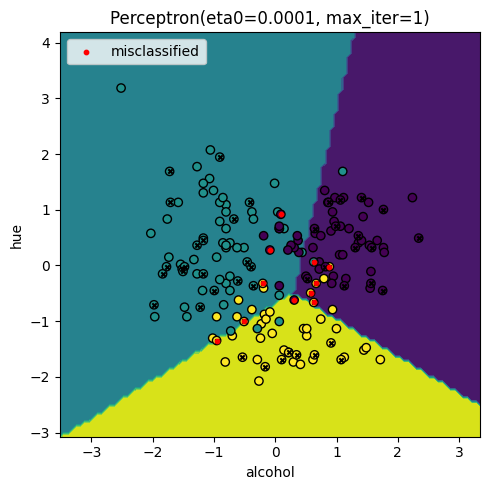

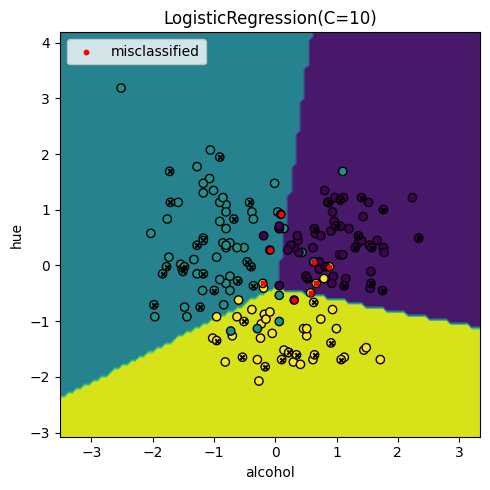

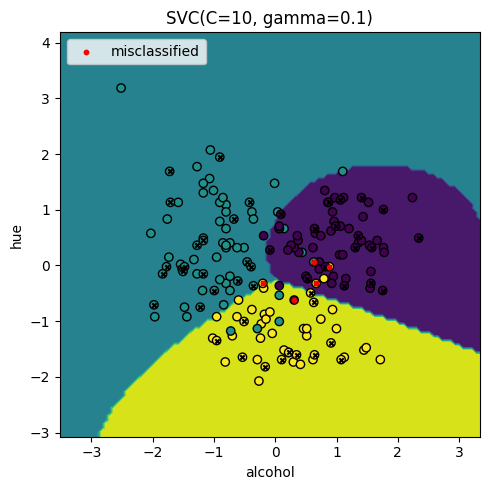

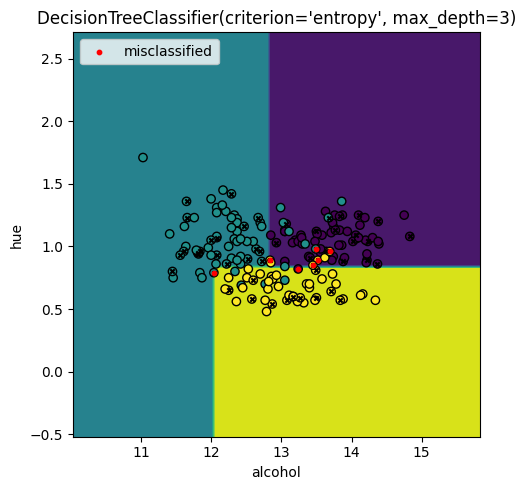

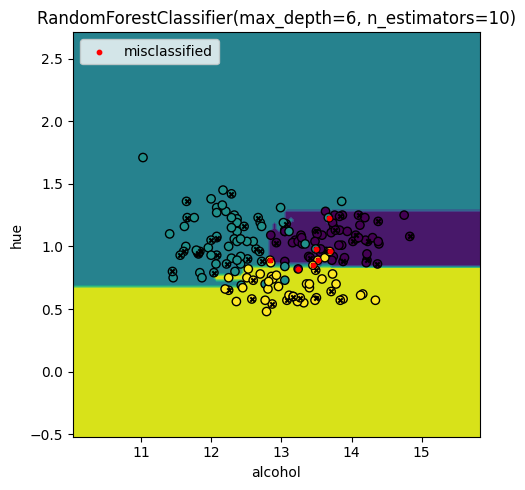

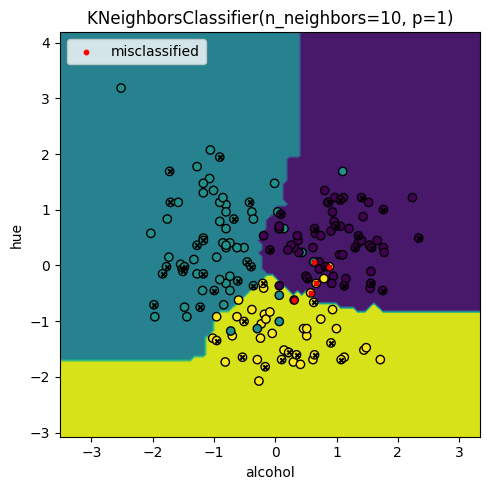

In [11]:
# ==============================================================================
# Plot the decision regions for all classifiers
# ==============================================================================
for classifier in [ppn,logR,svm,DT,forest,knn]:
    

    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
        
    if classifier in [DT,forest]:
        y_pred = classifier.predict(X_test)
        
        plot = DecisionBoundaryDisplay.from_estimator(
            estimator=classifier,
            X=X,
            alpha=1.0,
            ax=ax,
            response_method="predict",
            xlabel=feature_names[0],
            ylabel=feature_names[1],
        )

        plot.ax_.scatter(X[:, 0], X[:, 1], c=y, marker="o", edgecolor="k")

        # Highlight test samples
        plot.ax_.scatter(
            X_test[:, 0],
            X_test[:, 1],
            marker="x",
            s=10,
            c="k",
        )

        # Highlight misclassified test samples
        plot.ax_.scatter(
            X_test[y_test != y_pred, 0],
            X_test[y_test != y_pred, 1],
            marker="o",
            s=10,
            c="r",
            facecolors="none",
            label="misclassified",
        )

        plt.legend(loc="upper left")
        plt.title(str(classifier))
        plt.tight_layout()
        plt.show()
        
    else:
        y_pred = classifier.predict(X_test_sc)
    
        X_combined_sc = np.vstack((X_train_sc, X_test_sc))
        y_combined = np.hstack((y_train, y_test))
        
        plot = DecisionBoundaryDisplay.from_estimator(
            estimator=classifier,
            X=X_combined_sc,
            alpha=1.0,
            ax=ax,
            response_method="predict",
            xlabel=feature_names[0],
            ylabel=feature_names[1],
        )

        plot.ax_.scatter(X_combined_sc[:, 0], X_combined_sc[:, 1], c=y_combined, marker="o", edgecolor="k")

        # Highlight test samples
        plot.ax_.scatter(
            X_test_sc[:, 0],
            X_test_sc[:, 1],
            marker="x",
            s=10,
            c="k",
        )

        # Highlight misclassified test samples
        plot.ax_.scatter(
            X_test_sc[y_test != y_pred, 0],
            X_test_sc[y_test != y_pred, 1],
            marker="o",
            s=10,
            c="r",
            facecolors="none",
            label="misclassified",
        )

        plt.legend(loc="upper left")
        plt.title(str(classifier))
        plt.tight_layout()
        plt.show()

###### 

Text(0.5, 1.0, 'Number of misclassifications')

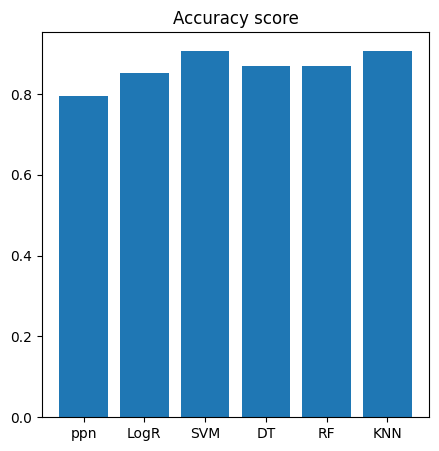

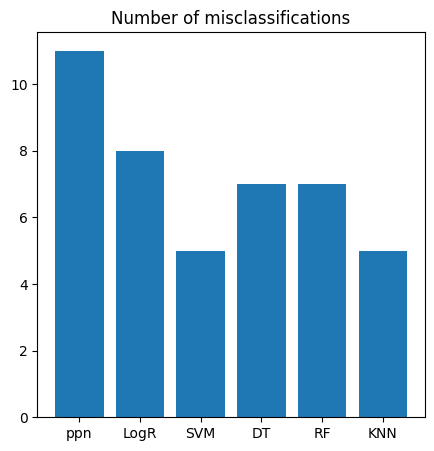

In [12]:
# ==============================================================================
# Plot accuracies and the number of misclassifications for all classifiers
# ==============================================================================

# Accuracy score
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
plt.bar(range(6),[ppn.score(X_test_sc, y_test), logR.score(X_test_sc, y_test), svm.score(X_test_sc, y_test), DT.score(X_test, y_test), forest.score(X_test, y_test), knn.score(X_test_sc, y_test)])
plt.xticks(range(6),['ppn','LogR','SVM','DT','RF', 'KNN'])
plt.title('Accuracy score')

# Number of misclassifications
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
plt.bar(range(6),[(y_test != y_pred_ppn).sum(), (y_test != y_pred_logR).sum(), (y_test != y_pred_SVC).sum(), (y_test != y_pred_DT).sum(), (y_test != y_pred_RF).sum(), (y_test != y_pred_KNN).sum()])
plt.xticks(range(6),['ppn','LogR','SVM','DT','RF', 'KNN'])
plt.title('Number of misclassifications')